# Phần 1.1 — IMDb: bức tranh ngành điện ảnh

Notebook này chỉ dùng **IMDb Non-Commercial Datasets** (`title.basics`, `title.ratings`), chưa dùng dữ liệu torrent. Dữ liệu đã được chuẩn bị bởi `src/03_imdb_catalog.py` → `data_clean/imdb_movies_all.parquet` (mọi phim `titleType = 'movie'`). Phim người lớn được loại bỏ.

Quy ước: phim nhiều thể loại (tối đa 3 trên IMDb) được **chia đều trọng số** khi tính cơ cấu, và được **tính ở mọi thể loại** khi so sánh điểm. Biểu đồ được lưu vào `plots/1_imdb/`.

In [1]:
# Tìm thư mục gốc dự án (chứa src/viz_style.py) để import phong cách biểu đồ dùng chung
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "viz_style.py").exists())
sys.path.insert(0, str(ROOT / "src"))
%matplotlib inline


## Nạp dữ liệu

In [2]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.ticker import FuncFormatter

import viz_style as V

V.setup()
FOLDER = "1_imdb"
SRC = "Nguồn: IMDb Non-Commercial Datasets (2026)."

df = duckdb.sql(f"""
    SELECT * FROM read_parquet('{(V.DC / "imdb_movies_all.parquet").as_posix()}')
    WHERE NOT is_adult
""").df()
genres_long = (df[["tconst", "genres", "start_year", "avg_rating", "num_votes"]]
               .dropna(subset=["genres"])
               .assign(genre=lambda d: d["genres"].str.split(","))
               .explode("genre"))
genres_long["weight"] = 1 / genres_long.groupby("tconst")["genre"].transform("size")
print(f"{len(df):,} phim (không tính phim người lớn), {df['num_votes'].notna().sum():,} có rating")

749,422 phim (không tính phim người lớn), 344,916 có rating


## 1. Mỗi năm có bao nhiêu phim được sản xuất?

  wrote plots\1_imdb\01_movies_per_year.png


WindowsPath('D:/dulieulon/plots/1_imdb/01_movies_per_year.png')

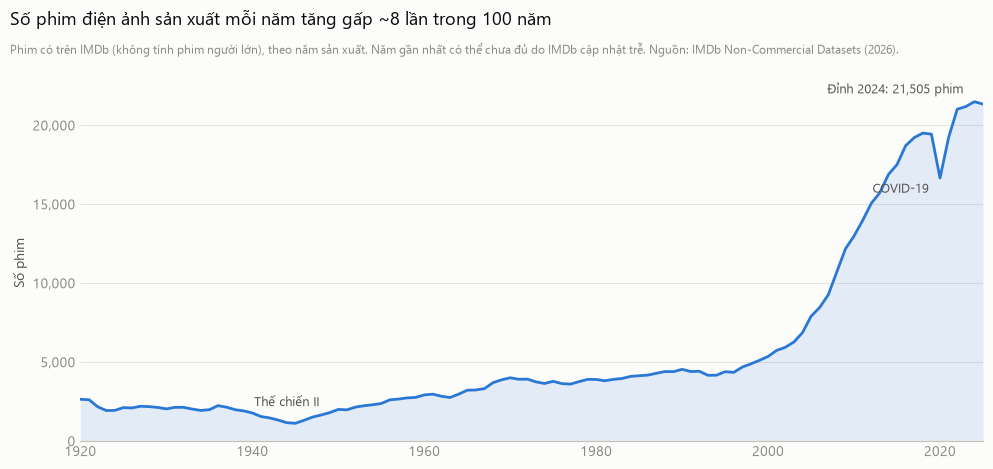

In [3]:
per_year = df[df["start_year"].between(1920, 2025)].groupby("start_year").size()
fig, ax = plt.subplots(figsize=(10, 4.8))
V.style_axes(ax)
ax.fill_between(per_year.index, per_year.values, color=V.BLUE, alpha=0.12, linewidth=0)
ax.plot(per_year.index, per_year.values, color=V.BLUE)
for yr, text, dx, dy, ha, va in [(1944, "Thế chiến II", 0, 10, "center", "bottom"),
                                 (2020, "COVID-19", -8, -4, "right", "top")]:
    ax.annotate(text, xy=(yr, per_year[yr]), xytext=(dx, dy), textcoords="offset points",
                ha=ha, va=va, color=V.INK2, fontsize=9)
peak = per_year.idxmax()
ax.annotate(f"Đỉnh {peak}: {per_year[peak]:,} phim", xy=(peak, per_year[peak]), xytext=(-8, 6),
            textcoords="offset points", ha="right", color=V.INK2, fontsize=9)
ax.yaxis.set_major_formatter(FuncFormatter(V.fmt_int))
ax.set_xlim(1920, 2025)
ax.set_ylim(0)
ax.set_ylabel("Số phim")
V.titles(fig, "Số phim điện ảnh sản xuất mỗi năm tăng gấp ~8 lần trong 100 năm",
         f"Phim có trên IMDb (không tính phim người lớn), theo năm sản xuất. Năm gần nhất có thể "
         f"chưa đủ do IMDb cập nhật trễ. {SRC}")
V.save(fig, FOLDER, "01_movies_per_year")

**Nhận xét.** Số phim tăng từ ~2.600 phim/năm (thập niên 1920) lên **~21.500 phim năm 2024** (gấp ~8 lần). Tăng mạnh nhất từ giữa thập niên 2000, khi máy quay số và nền tảng phát hành trực tuyến làm chi phí làm phim giảm. Hai lần sụt giảm rõ: **Thế chiến II** và **COVID-19 (2020)**, sau đó phục hồi ngay.

## 2. Cơ cấu thể loại thay đổi thế nào qua các thập niên?

  wrote plots\1_imdb\02_genre_share_by_decade.png


WindowsPath('D:/dulieulon/plots/1_imdb/02_genre_share_by_decade.png')

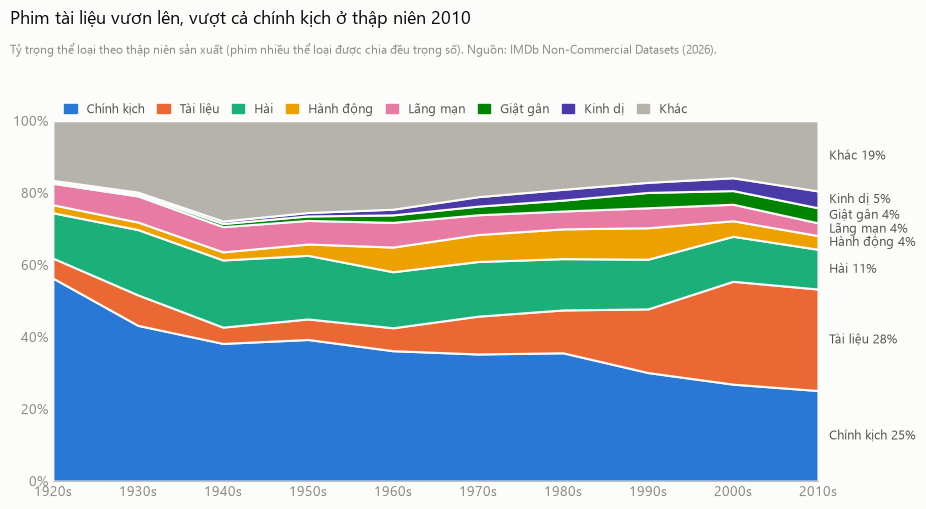

In [4]:
g = genres_long[genres_long["start_year"].between(1920, 2019)].copy()
g["decade"] = (g["start_year"] // 10) * 10
top = g.groupby("genre")["weight"].sum().nlargest(7).index.tolist()
g["genre_grp"] = np.where(g["genre"].isin(top), g["genre"], "Khác")
share = g.pivot_table(index="decade", columns="genre_grp", values="weight", aggfunc="sum").fillna(0)
share = share.div(share.sum(axis=1), axis=0)[top + ["Khác"]]
fig, ax = plt.subplots(figsize=(10, 5.2))
V.style_axes(ax, grid=None)
colors = V.CAT[:7] + [V.OTHER]
ax.stackplot(share.index, share.T.values, colors=colors, edgecolor=V.SURFACE, linewidth=1.5)
# nhãn trực tiếp ở mép phải, giữa mỗi dải
cum = share.iloc[-1].cumsum()
for name, c_top, val in zip(share.columns, cum, share.iloc[-1]):
    ax.annotate(f"{V.GENRE_VI.get(name, name)} {val:.0%}", xy=(share.index[-1], c_top - val / 2),
                xytext=(8, 0), textcoords="offset points", va="center", color=V.INK2, fontsize=9)
ax.set_xlim(share.index[0], share.index[-1])
ax.set_ylim(0, 1)
ax.set_xticks(share.index)
ax.set_xticklabels([f"{d}s" for d in share.index])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors]
ax.legend(handles, [V.GENRE_VI.get(n, n) for n in share.columns], ncol=8, loc="upper left",
          bbox_to_anchor=(0, 1.08), handlelength=1, columnspacing=1)
V.titles(fig, "Phim tài liệu vươn lên, vượt cả chính kịch ở thập niên 2010",
         f"Tỷ trọng thể loại theo thập niên sản xuất (phim nhiều thể loại được chia đều trọng số). {SRC}",
         extra=0.12)
fig.subplots_adjust(right=0.82)
V.save(fig, FOLDER, "02_genre_share_by_decade")

**Nhận xét.** Chính kịch từng chiếm >50% phim thập niên 1920, giảm dần còn ~25%. **Phim tài liệu** tăng mạnh từ thập niên 1990 và vượt chính kịch ở thập niên 2010 (28%) — một phần vì IMDb ghi nhận rất nhiều phim tài liệu nhỏ, độc lập. Hành động, kinh dị, giật gân cũng tăng dần.

## 3. Phim thường được chấm bao nhiêu điểm?

  wrote plots\1_imdb\03_rating_distribution.png


WindowsPath('D:/dulieulon/plots/1_imdb/03_rating_distribution.png')

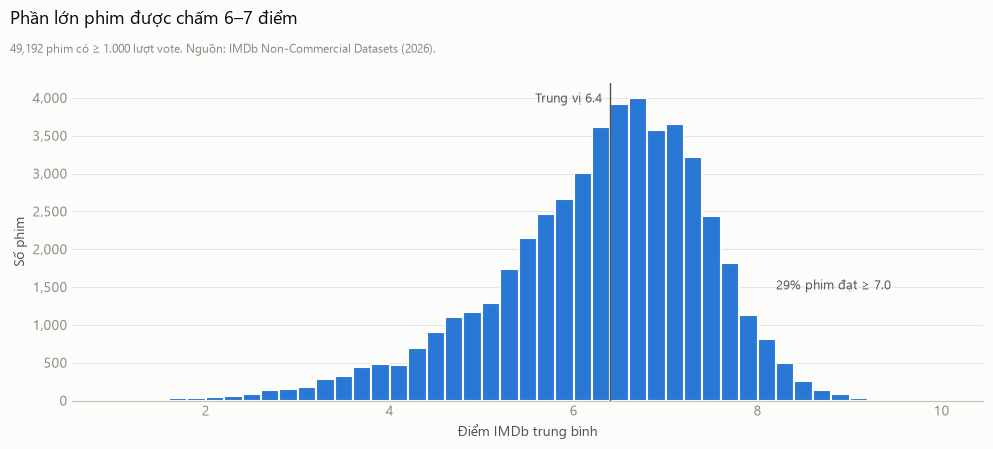

In [5]:
rated = df[df["num_votes"] >= 1000]
fig, ax = plt.subplots(figsize=(10, 4.6))
V.style_axes(ax)
bins = np.arange(1, 10.01, 0.2)
ax.hist(rated["avg_rating"], bins=bins, color=V.BLUE, edgecolor=V.SURFACE, linewidth=1.5)
med = rated["avg_rating"].median()
ax.axvline(med, color=V.INK2, linewidth=1)
ax.annotate(f"Trung vị {med:.1f}", xy=(med, ax.get_ylim()[1] * 0.97), xytext=(-6, 0),
            textcoords="offset points", color=V.INK2, fontsize=9, va="top", ha="right")
share_7 = (rated["avg_rating"] >= 7).mean()
ax.annotate(f"{share_7:.0%} phim đạt ≥ 7.0", xy=(8.2, ax.get_ylim()[1] * 0.35), color=V.INK2, fontsize=9)
ax.yaxis.set_major_formatter(FuncFormatter(V.fmt_int))
ax.set_xlabel("Điểm IMDb trung bình")
ax.set_ylabel("Số phim")
V.titles(fig, "Phần lớn phim được chấm 6–7 điểm",
         f"{len(rated):,} phim có ≥ 1.000 lượt vote. {SRC}")
V.save(fig, FOLDER, "03_rating_distribution")

**Nhận xét.** Với phim có ≥ 1.000 vote, phân bố lệch trái, **trung vị 6,4**; chỉ ~29% phim đạt ≥ 7,0. Phim điểm rất thấp hiếm hơn phim điểm cao — có thể vì phim dở ít người xem nên ít đạt mốc 1.000 vote (thiên lệch chọn mẫu).

## 4. Thể loại nào được chấm điểm cao nhất?

  wrote plots\1_imdb\04_rating_by_genre.png


WindowsPath('D:/dulieulon/plots/1_imdb/04_rating_by_genre.png')

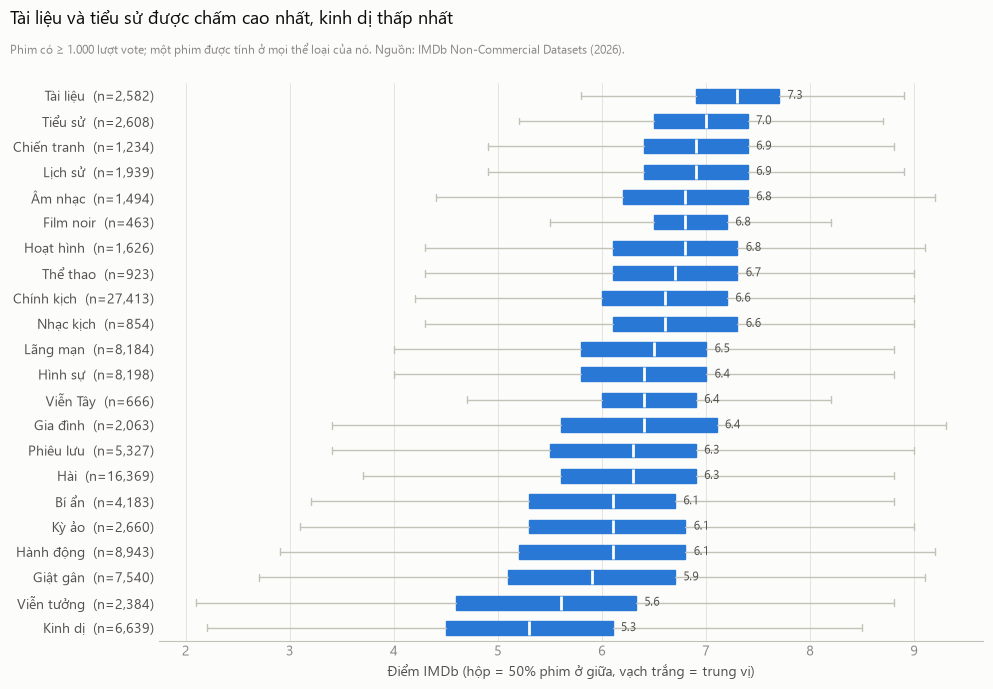

In [6]:
gr = genres_long[(genres_long["num_votes"] >= 1000) & ~genres_long["genre"].isin(["Adult", "News", "Reality-TV", "Talk-Show", "Game-Show"])]
counts = gr["genre"].value_counts()
gr = gr[gr["genre"].isin(counts[counts >= 300].index)]
order = gr.groupby("genre")["avg_rating"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 7))
V.style_axes(ax, grid="x")
data = [gr.loc[gr["genre"] == x, "avg_rating"].values for x in order]
bp = ax.boxplot(data, orientation="horizontal", widths=0.55, patch_artist=True, showfliers=False,
                medianprops=dict(color=V.SURFACE, linewidth=2),
                whiskerprops=dict(color=V.AXIS), capprops=dict(color=V.AXIS),
                boxprops=dict(facecolor=V.BLUE, edgecolor=V.BLUE))
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels([f"{V.GENRE_VI.get(x, x)}  (n={counts[x]:,})" for x in order], color=V.INK2)
for i, x in enumerate(order, 1):
    m = np.median(data[i - 1])
    ax.annotate(f"{m:.1f}", xy=(np.percentile(data[i - 1], 75), i), xytext=(6, 0),
                textcoords="offset points", va="center", color=V.INK2, fontsize=8.5)
ax.set_xlabel("Điểm IMDb (hộp = 50% phim ở giữa, vạch trắng = trung vị)")
V.titles(fig, "Tài liệu và tiểu sử được chấm cao nhất, kinh dị thấp nhất",
         f"Phim có ≥ 1.000 lượt vote; một phim được tính ở mọi thể loại của nó. {SRC}")
V.save(fig, FOLDER, "04_rating_by_genre")

**Nhận xét.** **Tài liệu (7,3)** và **tiểu sử (7,0)** dẫn đầu; **kinh dị (5,3)** và **viễn tưởng (5,6)** thấp nhất. Khoảng cách giữa thể loại cao nhất và thấp nhất ~2 điểm — lớn hơn nhiều so với biến động trong từng thể loại. Kinh dị có hộp rộng nhất: chất lượng phim kinh dị rất không đồng đều.

## 5. Phim có dài hơn theo thời gian không?

  wrote plots\1_imdb\05_runtime_ridgeline.png


WindowsPath('D:/dulieulon/plots/1_imdb/05_runtime_ridgeline.png')

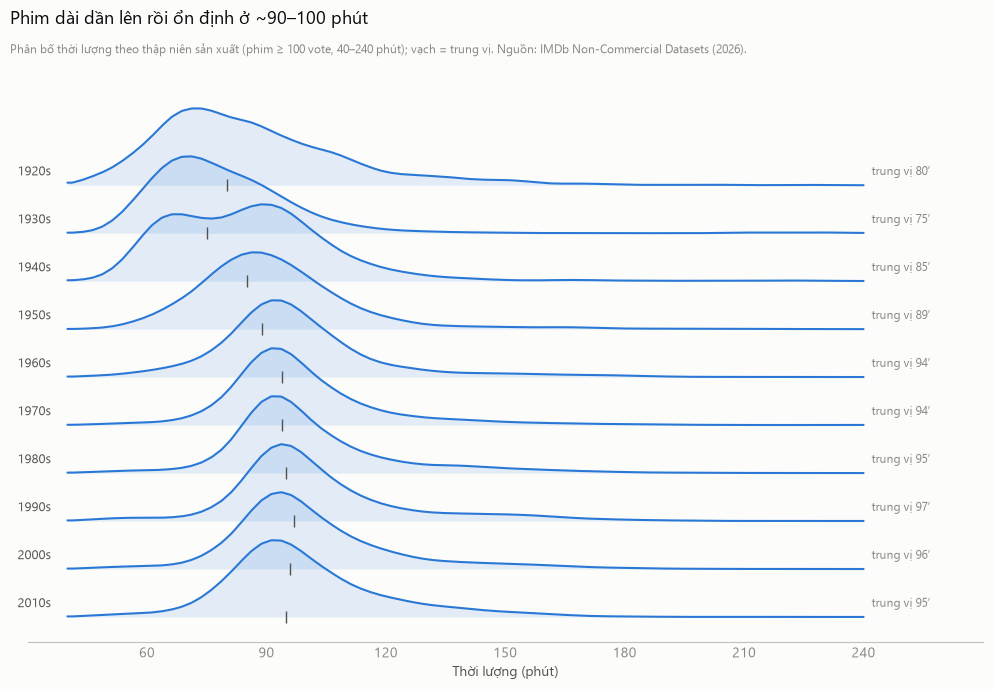

In [7]:
rt = df[(df["num_votes"] >= 100) & df["runtime_min"].between(40, 240) & df["start_year"].between(1920, 2019)].copy()
rt["decade"] = (rt["start_year"] // 10) * 10
decades = sorted(rt["decade"].unique())
xs = np.linspace(40, 240, 400)
fig, ax = plt.subplots(figsize=(10, 7))
V.style_axes(ax, grid=None)
step = 1.0
for i, dec in enumerate(decades[::-1]):
    vals = rt.loc[rt["decade"] == dec, "runtime_min"].values
    hist, edges = np.histogram(vals, bins=80, range=(40, 240), density=True)
    kde = np.convolve(hist, np.hanning(11) / np.hanning(11).sum(), mode="same")
    centers = (edges[:-1] + edges[1:]) / 2
    y = np.interp(xs, centers, kde)
    y = y / y.max() * 1.6
    base = i * step
    ax.fill_between(xs, base, base + y, color=V.BLUE, alpha=0.12, linewidth=0, zorder=len(decades) - i)
    ax.plot(xs, base + y, color=V.BLUE, linewidth=1.5, zorder=len(decades) - i)
    ax.plot(np.median(vals), base, "|", color=V.INK2, markersize=8, zorder=50)
    ax.text(36, base + 0.15, f"{dec}s", ha="right", va="bottom", color=V.INK2, fontsize=9)
    ax.text(242, base + 0.15, f"trung vị {np.median(vals):.0f}′", ha="left", va="bottom", color=V.MUTED, fontsize=8.5)
ax.set_yticks([])
ax.set_xlim(30, 270)
ax.set_xticks(range(60, 241, 30))
ax.set_xlabel("Thời lượng (phút)")
V.titles(fig, "Phim dài dần lên rồi ổn định ở ~90–100 phút",
         f"Phân bố thời lượng theo thập niên sản xuất (phim ≥ 100 vote, 40–240 phút); vạch = trung vị. {SRC}")
V.save(fig, FOLDER, "05_runtime_ridgeline")

**Nhận xét.** Trung vị thời lượng tăng từ **75–80 phút** (1920–30s) lên **~95 phút** từ thập niên 1980 và ổn định từ đó. Phân bố hẹp dần: chuẩn "phim truyện ~90 phút" được hình thành rõ rệt sau thập niên 1950.

## 6. Sự chú ý của khán giả phân bố đều hay tập trung?

  wrote plots\1_imdb\06_votes_lorenz.png


WindowsPath('D:/dulieulon/plots/1_imdb/06_votes_lorenz.png')

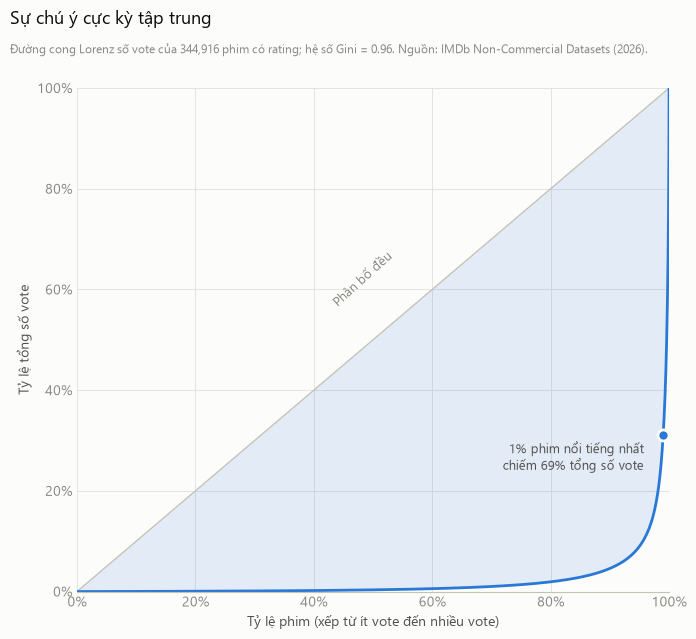

In [8]:
v = np.sort(df["num_votes"].dropna().values)
cum_votes = np.cumsum(v) / v.sum()
cum_movies = np.arange(1, len(v) + 1) / len(v)
gini = 1 - 2 * np.trapezoid(cum_votes, cum_movies)
top1 = v[int(len(v) * 0.99):].sum() / v.sum()
fig, ax = plt.subplots(figsize=(7, 6.5))
V.style_axes(ax, grid="both")
ax.plot([0, 1], [0, 1], color=V.AXIS, linewidth=1)
ax.fill_between(cum_movies, cum_votes, cum_movies, color=V.BLUE, alpha=0.12, linewidth=0)
ax.plot(cum_movies, cum_votes, color=V.BLUE)
ax.annotate("Phân bố đều", xy=(0.55, 0.55), xytext=(-6, 6), textcoords="offset points",
            rotation=42, color=V.MUTED, fontsize=9, ha="right")
ax.annotate(f"1% phim nổi tiếng nhất\nchiếm {top1:.0%} tổng số vote", xy=(0.99, 1 - top1),
            xytext=(-14, -4), textcoords="offset points", ha="right", va="top", color=V.INK2, fontsize=9)
ax.plot(0.99, 1 - top1, "o", markersize=8, color=V.BLUE, markeredgecolor=V.SURFACE, markeredgewidth=2)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("Tỷ lệ phim (xếp từ ít vote đến nhiều vote)")
ax.set_ylabel("Tỷ lệ tổng số vote")
V.titles(fig, "Sự chú ý cực kỳ tập trung",
         f"Đường cong Lorenz số vote của {len(v):,} phim có rating; hệ số Gini = {gini:.2f}. {SRC}")
V.save(fig, FOLDER, "06_votes_lorenz")

**Nhận xét.** Cực kỳ tập trung: **1% phim nổi tiếng nhất chiếm ~69% tổng số vote**, hệ số Gini ≈ 0,96 (cao hơn bất kỳ phân bố thu nhập quốc gia nào). Đây là đặc trưng "đuôi dài" của ngành giải trí: vài bom tấn hút gần hết sự chú ý.

## 7. Thể loại nào hay đi cùng nhau?

  wrote plots\1_imdb\07_genre_cooccurrence.png


WindowsPath('D:/dulieulon/plots/1_imdb/07_genre_cooccurrence.png')

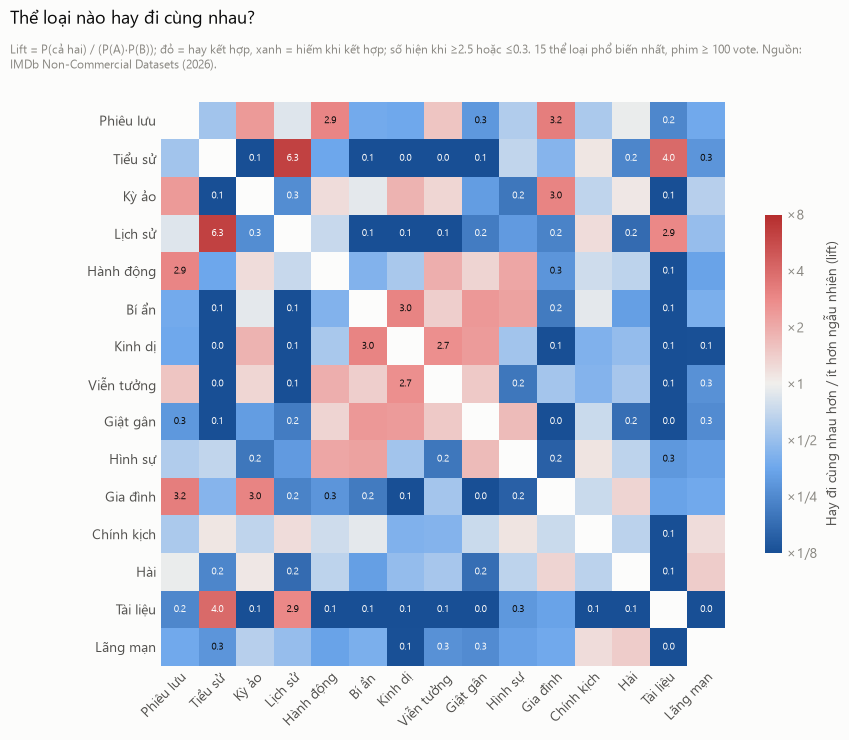

In [9]:
multi = genres_long[genres_long["num_votes"] >= 100]
top15 = multi["genre"].value_counts().head(15).index
sets = multi[multi["genre"].isin(top15)].groupby("tconst")["genre"].apply(set)
n = len(sets)
p = {x: sum(x in s for s in sets) / n for x in top15}
lift = pd.DataFrame(index=top15, columns=top15, dtype=float)
for a in top15:
    for b in top15:
        if a != b:
            pab = sum((a in s) and (b in s) for s in sets) / n
            lift.loc[a, b] = pab / (p[a] * p[b])
order = lift.mean().sort_values(ascending=False).index
lift = lift.loc[order, order]
fig, ax = plt.subplots(figsize=(9, 8))
V.style_axes(ax, grid=None)
ax.spines["bottom"].set_visible(False)
im = ax.imshow(np.log2(lift.values.astype(float)), cmap=V.DIV, norm=TwoSlopeNorm(0, -3, 3))
labels = [V.GENRE_VI.get(x, x) for x in lift.index]
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right", rotation_mode="anchor", color=V.INK2)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, color=V.INK2)
for i in range(len(labels)):
    for j in range(len(labels)):
        val = lift.values[i, j]
        if not np.isnan(val) and (val >= 2.5 or val <= 0.3):
            ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=7.5,
                    color=V.SURFACE if abs(np.log2(val)) > 1.8 else V.INK)
cb = fig.colorbar(im, ax=ax, shrink=0.6, ticks=[-3, -2, -1, 0, 1, 2, 3])
cb.ax.set_yticklabels(["×1/8", "×1/4", "×1/2", "×1", "×2", "×4", "×8"], color=V.MUTED)
cb.outline.set_visible(False)
cb.set_label("Hay đi cùng nhau hơn / ít hơn ngẫu nhiên (lift)", color=V.INK2)
V.titles(fig, "Thể loại nào hay đi cùng nhau?",
         f"Lift = P(cả hai) / (P(A)·P(B)); đỏ = hay kết hợp, xanh = hiếm khi kết hợp; số hiện khi ≥2.5 hoặc ≤0.3. "
         f"15 thể loại phổ biến nhất, phim ≥ 100 vote. {SRC}")
fig.subplots_adjust(bottom=0.16)
V.save(fig, FOLDER, "07_genre_cooccurrence")

**Nhận xét.** Các cặp kết hợp mạnh: **Tiểu sử + Lịch sử (×6,3)**, **Tiểu sử + Tài liệu (×4,0)**, **Phiêu lưu + Gia đình (×3,2)**, **Kỳ ảo + Gia đình (×3,0)**, **Bí ẩn + Kinh dị (×3,0)**. Ngược lại **Tài liệu gần như không kết hợp** với thể loại hư cấu nào (cột/hàng xanh đậm).

## 8. Phim nổi tiếng có được chấm cao hơn không?

  wrote plots\1_imdb\08_votes_vs_rating.png


WindowsPath('D:/dulieulon/plots/1_imdb/08_votes_vs_rating.png')

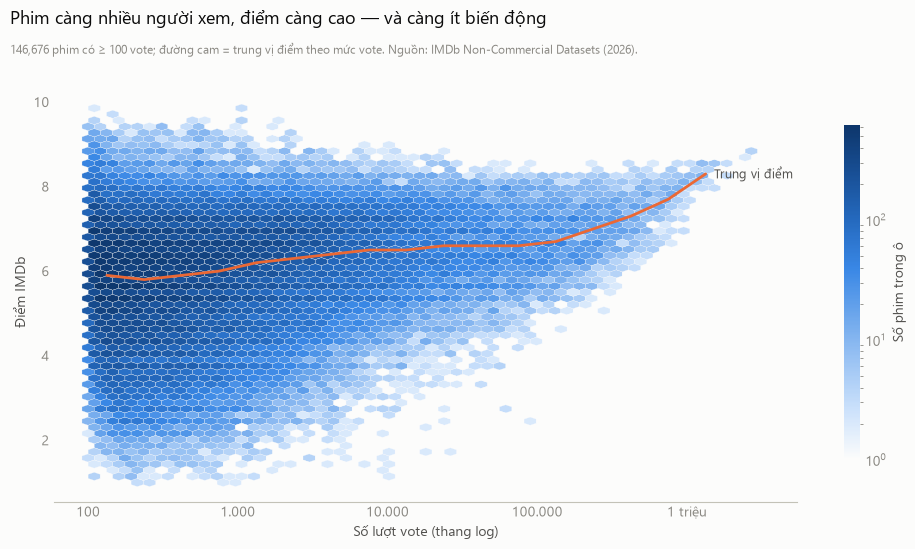

In [10]:
h = df[df["num_votes"] >= 100]
fig, ax = plt.subplots(figsize=(10, 5.6))
V.style_axes(ax, grid=None)
hb = ax.hexbin(np.log10(h["num_votes"]), h["avg_rating"], gridsize=55, cmap=V.SEQ, norm=LogNorm(),
               mincnt=1, linewidths=0.2, edgecolors=V.SURFACE)
med = h.groupby(np.floor(np.log10(h["num_votes"]) * 4) / 4)["avg_rating"].median()
med = med[h.groupby(np.floor(np.log10(h["num_votes"]) * 4) / 4).size() >= 30]
ax.plot(med.index + 0.125, med.values, color=V.ORANGE, linewidth=2)
ax.annotate("Trung vị điểm", xy=(med.index[-1] + 0.125, med.values[-1]), xytext=(6, 0),
            textcoords="offset points", va="center", color=V.INK2, fontsize=9)
ax.set_xticks([2, 3, 4, 5, 6])
ax.set_xticklabels(["100", "1.000", "10.000", "100.000", "1 triệu"])
ax.set_xlabel("Số lượt vote (thang log)")
ax.set_ylabel("Điểm IMDb")
cb = fig.colorbar(hb, ax=ax, shrink=0.8)
cb.outline.set_visible(False)
cb.set_label("Số phim trong ô", color=V.INK2)
V.titles(fig, "Phim càng nhiều người xem, điểm càng cao — và càng ít biến động",
         f"{len(h):,} phim có ≥ 100 vote; đường cam = trung vị điểm theo mức vote. {SRC}")
V.save(fig, FOLDER, "08_votes_vs_rating")

**Nhận xét.** Có: trung vị điểm tăng từ ~6 (phim ~100 vote) lên **> 8 (phim > 1 triệu vote)**, và độ phân tán thu hẹp. Lưu ý quan hệ hai chiều: phim hay thu hút nhiều người xem, và phim nhiều người xem được đánh giá bởi đám đông rộng hơn — đây là **tương quan**, không phải nhân quả.

## Tóm tắt phần IMDb

| Khía cạnh | Phát hiện chính |
|---|---|
| Quy mô | Số phim/năm tăng ~8 lần trong 100 năm; COVID làm giảm ~15% năm 2020 |
| Thể loại | Tài liệu vươn lên vượt chính kịch; các cặp thể loại có "logic" kết hợp rõ |
| Chất lượng | Trung vị 6,4; tài liệu/tiểu sử cao nhất, kinh dị thấp nhất |
| Thời lượng | Hội tụ về chuẩn ~95 phút từ thập niên 1980 |
| Sự chú ý | Cực kỳ tập trung (Gini 0,96); phim nổi tiếng được chấm cao hơn |